In [30]:
from ISLP import load_data
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge, LassoCV, Lasso
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

In [2]:
College = load_data('College')
College['Private'] = College['Private'].map({'Yes': 1, 'No': 0}).astype(int)
College_train, College_valid = train_test_split(College, test_size=0.3, random_state=42)

In [3]:
preds = College.columns.drop('Apps')
X_train = College_train[preds]
y_train = College_train['Apps']
model = sm.OLS(y_train, X_train)
results = model.fit()


In [4]:
X_valid = College_valid[preds]
y_valid = College_valid['Apps']
valid_pred = results.predict(X_valid)
mse = mean_squared_error(y_valid, valid_pred)
mse

1933004.0624221277

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_valid)

In [6]:
ridge = Ridge()

In [7]:
param_grid = {'alpha': np.logspace(-3, 3, 50)}

In [8]:
grid_search = GridSearchCV(ridge, param_grid, cv=5, scoring='neg_mean_squared_error')

In [9]:
grid_search.fit(X_train_scaled, y_train)
best_alpha = grid_search.best_params_['alpha']
best_alpha


0.001

In [10]:
final_model = Ridge(alpha=best_alpha)
final_model.fit(X_train_scaled, y_train)

y_pred = final_model.predict(X_test_scaled)
mse = mean_squared_error(y_valid, valid_pred)
mse

1933004.0624221277

In [24]:
lasso_cv = LassoCV(alphas=np.logspace(-3, 2, 100), cv=5, max_iter=10000, random_state=42)
lasso_cv.fit(X_train_scaled, y_train)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

LassoCV(alphas=array([1.00000000e-03, 1.12332403e-03, 1.26185688e-03, 1.41747416e-03,
       1.59228279e-03, 1.78864953e-03, 2.00923300e-03, 2.25701972e-03,
       2.53536449e-03, 2.84803587e-03, 3.19926714e-03, 3.59381366e-03,
       4.03701726e-03, 4.53487851e-03, 5.09413801e-03, 5.72236766e-03,
       6.42807312e-03, 7.22080902e-03, 8.11130831e-03, 9.11162756e-03,
       1.02353102e-02, 1.14975700e-0...
       6.89261210e+00, 7.74263683e+00, 8.69749003e+00, 9.77009957e+00,
       1.09749877e+01, 1.23284674e+01, 1.38488637e+01, 1.55567614e+01,
       1.74752840e+01, 1.96304065e+01, 2.20513074e+01, 2.47707636e+01,
       2.78255940e+01, 3.12571585e+01, 3.51119173e+01, 3.94420606e+01,
       4.43062146e+01, 4.97702356e+01, 5.59081018e+01, 6.28029144e+01,
       7.05480231e+01, 7.92482898e+01, 8.90215085e+01, 1.00000000e+02]),
        cv=5, max_iter=10000, random_state=42)

In [12]:
best_alpha_lasso = lasso_cv.alpha_
best_alpha_lasso

0.001

In [14]:
y_pred_lasso = lasso_cv.predict(X_test_scaled)

In [15]:
mse_lasso = mean_squared_error(y_valid, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
rmse_lasso

1389.8926592043686

In [26]:
non_zero_coefs = np.sum(lasso_cv.coef_ != 0)
print(f"Number of non-zero coefficients: {non_zero_coefs}")

Number of non-zero coefficients: 17


In [32]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('ridge', Ridge())
])

In [35]:
param_grid = {
    'pca__n_components': range(1, 18)
}

In [36]:
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)

,estimator,"Pipeline(step...e', Ridge())])"
,param_grid,"{'pca__n_components': range(1, 18)}"
,scoring,'neg_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [38]:
best_n_components = grid.best_params_['pca__n_components']
best_n_components

17

In [41]:
y_pred = grid.predict(X_valid)
mse = mean_squared_error(y_valid, y_pred)
rmse = np.sqrt(mse)
rmse

1378.4217608400795

In [43]:
from sklearn.cross_decomposition import PLSRegression
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pls', PLSRegression())
])
param_grid = {
    'pls__n_components': list(range(1, 18))
}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)

best_n_components = grid.best_params_['pls__n_components']
print(f"Best number of PLS components: {best_n_components}")

y_pred = grid.predict(X_valid)
mse = mean_squared_error(y_valid, y_pred)
rmse = np.sqrt(mse)
print(f"Validation RMSE: {rmse:.2f}")

Best number of PLS components: 17
Validation RMSE: 1389.89


In [44]:
#PCA worked the best, though we cannot predict the applicants very accurately 

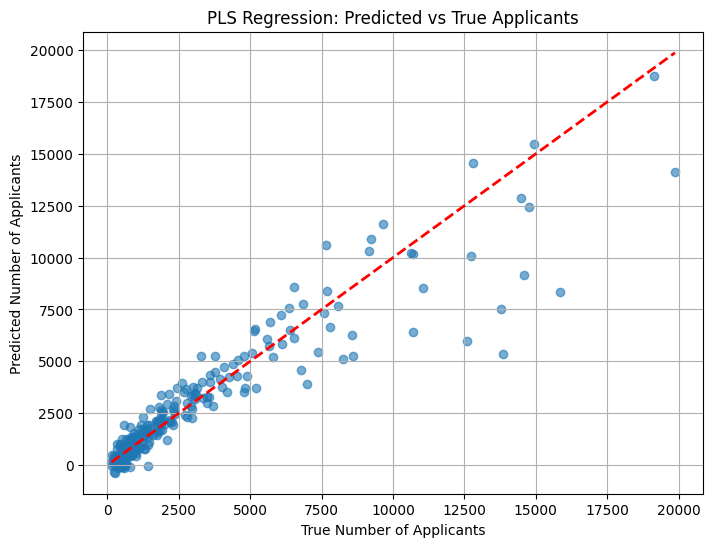

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_valid, y_pred, alpha=0.6)
plt.plot([y_valid.min(), y_valid.max()], [y_valid.min(), y_valid.max()], 'r--', lw=2)

plt.xlabel('True Number of Applicants')
plt.ylabel('Predicted Number of Applicants')
plt.title('PLS Regression: Predicted vs True Applicants')
plt.grid(True)
